## Step 1 — Import the Tools We Need

In [3]:
# numpy helps us work with numbers and arrays
import numpy as np

# matplotlib is what we use to draw charts and pictures
import matplotlib.pyplot as plt

# load_digits gives us a real dataset of handwritten digit images, built into scikit-learn
from sklearn.datasets import load_digits

# train_test_split splits our data into a training set and a test set
from sklearn.model_selection import train_test_split

# tensorflow is the library that keras (the tool we'll build our networks with) lives inside
import tensorflow as tf

# keras is the friendly, high-level part of tensorflow used to build neural networks
from tensorflow import keras

# layers gives us the building blocks (Dense, Flatten, Conv2D, MaxPooling2D) we'll stack to build our networks
from tensorflow.keras import layers

# lock in the "randomness" so everyone gets the exact same results every time
np.random.seed(42)
tf.random.set_seed(42)

# a simple message to confirm everything loaded properly, and which tensorflow version we have
print("TensorFlow version:", tf.__version__)
print("Ready to go!")

TensorFlow version: 2.21.0
Ready to go!


In [4]:

digits = load_digits()
all_images = digits.images
all_labels = digits.target
print("Images shape:", all_images.shape)
print("Example label:", all_labels[0])

Images shape: (1797, 8, 8)
Example label: 0


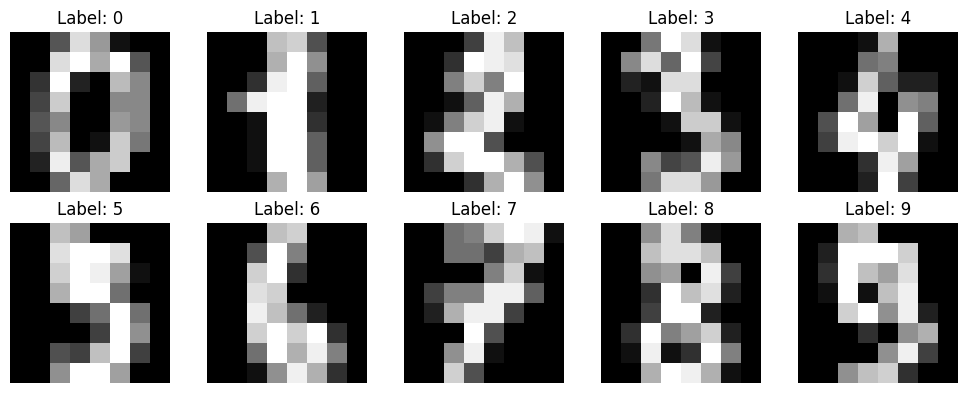

In [5]:

plt.figure(figsize=(10, 4))
for i in range(10):

    plt.subplot(2, 5, i + 1)
    plt.imshow(all_images[i], cmap="gray")
    plt.title(f"Label: {all_labels[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:

scaled_images = all_images / 16.0
train_images, test_images, train_labels, test_labels = train_test_split(
    scaled_images, all_labels, test_size=0.2, random_state=42, stratify=all_labels
)
print("Training images:", train_images.shape[0])
print("Test images:", test_images.shape[0])

Training images: 1437
Test images: 360


In [8]:

ann_model = keras.Sequential([

    
    keras.Input(shape=(8, 8)),
    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="ANN")
ann_model.summary()

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
ann_model.compile(
    
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("ANN compiled!")

ANN compiled!


In [10]:

ann_history = ann_model.fit(
    train_images,                  
    train_labels,                  
    epochs=40,                     
    batch_size=16,                 
    validation_split=0.15,         
    verbose=0,                     

)
print("ANN training finished!")

ANN training finished!


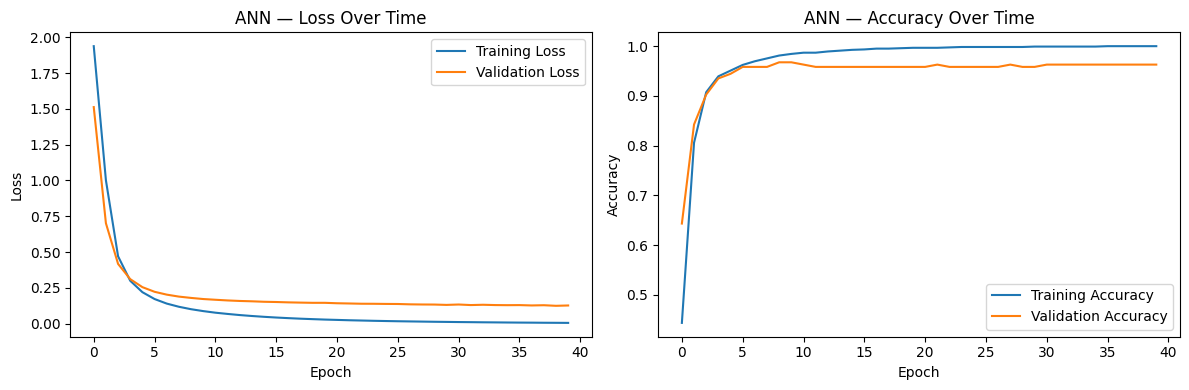

In [11]:

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ann_history.history["loss"], label="Training Loss")


plt.plot(ann_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN — Loss Over Time")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(ann_history.history["accuracy"], label="Training Accuracy")
plt.plot(ann_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN — Accuracy Over Time")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:

ann_test_loss, ann_test_accuracy = ann_model.evaluate(test_images, test_labels, verbose=0)
print(f"ANN test loss: {ann_test_loss:.4f}")
print(f"ANN test accuracy: {ann_test_accuracy * 100:.2f}%")

ANN test loss: 0.0874
ANN test accuracy: 97.50%


In [16]:
train_images_cnn = train_images.reshape(-1, 8, 8, 1)
test_images_cnn = test_images.reshape(-1, 8, 8, 1)
print("ANN-shaped training images:", train_images.shape)
print("CNN-shaped training images:", train_images_cnn.shape)

ANN-shaped training images: (1437, 8, 8)
CNN-shaped training images: (1437, 8, 8, 1)


In [17]:
cnn_model = keras.Sequential([
    keras.Input(shape=(8, 8, 1)),
    layers.Conv2D(8, (3, 3), activation="relu", padding="same"),

    
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="CNN")

cnn_model.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 8)        │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 16)       │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,658 (14.29 KB)

 Trainable params: 3,658 (14.29 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
cnn_model.compile(

    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("CNN compiled!")

CNN compiled!


In [20]:

cnn_history = cnn_model.fit(
    train_images_cnn,               
    train_labels,                   
    epochs=40,                      
    batch_size=16,                 
    validation_split=0.15,          
    verbose=0,                      
)


print("CNN training finished!")

CNN training finished!


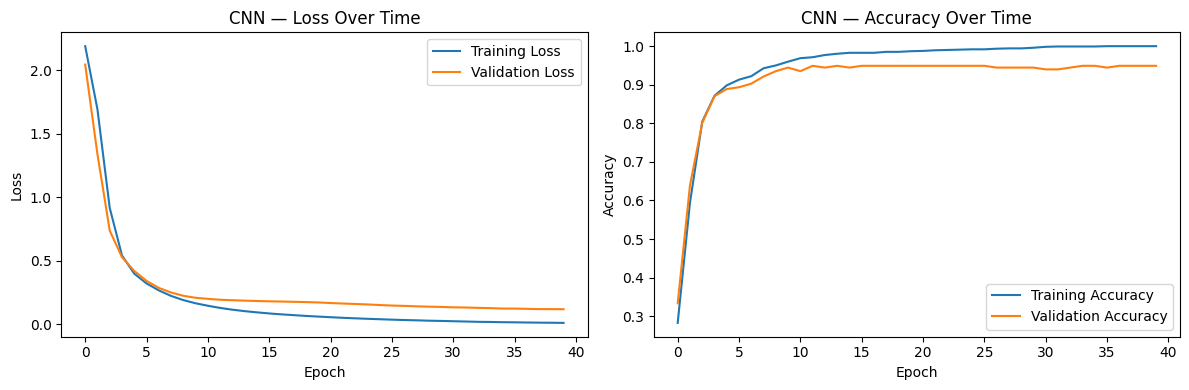

In [21]:

plt.figure(figsize=(12, 4))

#  left chart:
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN — Loss Over Time")
plt.legend()

# right chart:
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN — Accuracy Over Time")
plt.legend()


plt.tight_layout()
plt.show()

In [22]:

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_images_cnn, test_labels, verbose=0)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy * 100:.2f}%")

CNN test loss: 0.0771
CNN test accuracy: 98.06%


In [23]:

ann_param_count = ann_model.count_params()
cnn_param_count = cnn_model.count_params()
print(f"{'Model':<8}{'Test Accuracy':>16}{'Parameters':>14}")
print(f"{'ANN':<8}{ann_test_accuracy * 100:>15.2f}%{ann_param_count:>14,}")
print(f"{'CNN':<8}{cnn_test_accuracy * 100:>15.2f}%{cnn_param_count:>14,}")

Model      Test Accuracy    Parameters
ANN               97.50%         6,570
CNN               98.06%         3,658


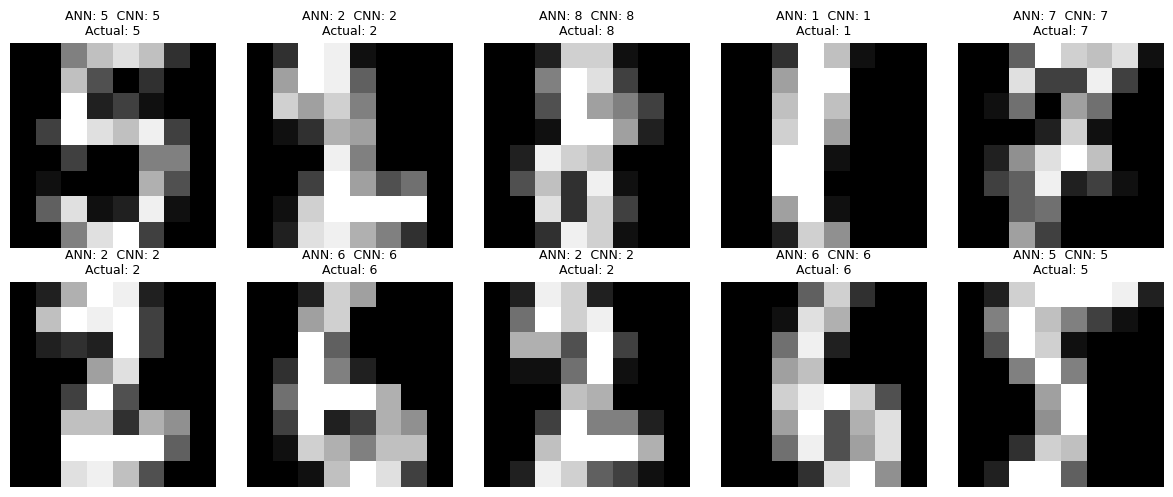

In [24]:

ann_predictions = np.argmax(ann_model.predict(test_images, verbose=0), axis=1)
cnn_predictions = np.argmax(cnn_model.predict(test_images_cnn, verbose=0), axis=1)
plt.figure(figsize=(12, 5))
for i in range(10):

    plt.subplot(2, 5, i + 1)
    plt.imshow(test_images[i], cmap="gray")
    ann_correct = ann_predictions[i] == test_labels[i]
    cnn_correct = cnn_predictions[i] == test_labels[i]

    ann_color = "green" if ann_correct else "red"
    cnn_color = "green" if cnn_correct else "red"
    plt.title(f"ANN: {ann_predictions[i]}  CNN: {cnn_predictions[i]}\nActual: {test_labels[i]}", fontsize=9)

    plt.axis("off")


plt.tight_layout()
plt.show()

The ANN and CNN disagreed on 10 out of 360 test images


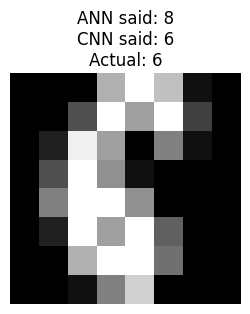

In [25]:

disagreement_indices = np.where(ann_predictions != cnn_predictions)[0]
print(f"The ANN and CNN disagreed on {len(disagreement_indices)} out of {len(test_labels)} test images")
if len(disagreement_indices) > 0:
    first_disagreement = disagreement_indices[0]
    plt.figure(figsize=(3, 3))
    plt.imshow(test_images[first_disagreement], cmap="gray")
    plt.title(
        f"ANN said: {ann_predictions[first_disagreement]}\n"
        f"CNN said: {cnn_predictions[first_disagreement]}\n"
        f"Actual: {test_labels[first_disagreement]}"
    )
    plt.axis("off")
    plt.show()
else:
    print("The ANN and CNN agreed on every single test image this run!")